# 02 — Baselines and Leakage-Safe Validation

[Previous](./01_Exploratory_Data_Analysis.ipynb) | [Repository guide](../README.md) | [Next](./03_Missing_Values_and_Scaling.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** build a minimum reference score and choose a reliable way to compare later methods.

- Official competition metric: **F1 score**.
- IDs are excluded because every ID is unique.
- `solution.csv` is never read.
- Preprocessing is fitted inside each validation split.

In [1]:
from pathlib import Path
from zipfile import BadZipFile, ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TARGET = "is_scored"
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd()
pd.set_option("display.float_format", lambda value: f"{value:.4f}")
plt.style.use("seaborn-v0_8-whitegrid")


In [2]:
def data_directories(start="."):
    start = Path(start).resolve()
    candidates = [
        start / "data", start.parent / "data", start,
        Path("/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"),
        Path("/kaggle/input/penalty-kick-outcome-prediction-challenge"),
        Path("/content/data"), Path("/content"),
    ]
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        candidates.extend(path for path in kaggle_input.iterdir() if path.is_dir())
    return list(dict.fromkeys(candidates))

def load_train_test(start="."):
    candidates = data_directories(start)
    for folder in candidates:
        train_path, test_path = folder / "train.csv", folder / "test.csv"
        if train_path.exists() and test_path.exists():
            return pd.read_csv(train_path), pd.read_csv(test_path), str(folder)
    for folder in candidates:
        if not folder.is_dir():
            continue
        for archive_path in sorted(folder.glob("*.zip")):
            try:
                with ZipFile(archive_path) as archive:
                    if {"train.csv", "test.csv"}.issubset(archive.namelist()):
                        with archive.open("train.csv") as file:
                            train = pd.read_csv(file)
                        with archive.open("test.csv") as file:
                            test = pd.read_csv(file)
                        return train, test, f"{archive_path} (ZIP)"
            except BadZipFile:
                pass
    raise FileNotFoundError("Attach the competition data or upload train.csv and test.csv.")

In [3]:
train, test, data_source = load_train_test(PROJECT_ROOT)
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)
print(f"Source: {data_source}")
print(f"Train: {train.shape} | Test: {test.shape}")
print("solution.csv: intentionally not loaded")

Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
solution.csv: intentionally not loaded


## 1. How are the metrics calculated?

Only `train.csv` has known answers. Five-fold validation divides it into five parts. Each time, four parts train the model and the untouched part is predicted. After five rounds, every training row has an **out-of-fold (OOF)** prediction made without training on that row.

At threshold `0.50`, probabilities become `0/1` predictions and are compared with `train["is_scored"]`:

- **Precision = TP / (TP + FP):** when we predict “scored,” how often are we correct?
- **Recall = TP / (TP + FN):** how many actual scores did we find?
- **F1 = 2 × precision × recall / (precision + recall):** balances precision and recall.
- **Accuracy:** share of all `0/1` predictions that are correct.
- **ROC-AUC:** probability-ranking quality across thresholds.
- **Log loss:** probability quality; confident mistakes cost more.

These are validation scores, not competition-test scores. `solution.csv` is never read. A true test score exists only after Kaggle evaluates a submission.


In [4]:
target_table = train[TARGET].value_counts().sort_index().to_frame("rows")
target_table["percent"] = target_table["rows"].div(len(train)).mul(100)
display(target_table)
print("The 55/45 split is only mildly imbalanced, but F1 still reveals whether class 1 is being found.")

,rows,percent
is_scored,,
0,10999,54.9950
1,9001,45.0050


The 55/45 split is only mildly imbalanced, but F1 still reveals whether class 1 is being found.


## 2. Why define validation before finishing preprocessing?

Validation is the measuring system, not a preprocessing treatment. We need that system first so every later choice—imputation, scaling, encoding, features, selection, outliers, and balancing—is judged on the same unseen folds.

**Data leakage** means training uses information unavailable at prediction time. Example: calculating an imputation value or target encoding from all rows before splitting.

**Overfitting** means a model learns training-specific detail that does not generalize, even when the validation procedure itself is honest. Example: a needlessly complex model memorizes noise and scores worse on untouched folds.

The pipeline prevents leakage by fitting preprocessing only on each fold’s training rows. Validation then reveals overfitting as a train-to-validation performance gap or unstable fold scores.


In [5]:
FEATURES = [column for column in train.columns if column not in {TARGET, *ID_COLUMNS}]
NUMERICAL = train[FEATURES].select_dtypes(include=np.number).columns.tolist()
CATEGORICAL = [column for column in FEATURES if column not in NUMERICAL]

def build_pipeline(feature_columns, model):
    numerical = [column for column in feature_columns if column in NUMERICAL]
    categorical = [column for column in feature_columns if column in CATEGORICAL]
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numerical),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("one_hot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical),
    ])
    return Pipeline([("preprocessing", preprocessing), ("model", model)])

def metric_row(name, y_true, probabilities, threshold=0.50):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "method": name,
        "f1": f1_score(y_true, predictions, zero_division=0),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "accuracy": accuracy_score(y_true, predictions),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "log_loss": log_loss(y_true, probabilities),
    }

## 3. Baselines

A **baseline** is a simple reference that a useful model should beat. **Logistic regression** learns a weight for each input and converts the weighted result into a probability from `0` to `1`.

Each result below uses **out-of-fold (OOF) predictions**: every row is predicted by a model that did not train on that row.

| Method | What it does | Why include it |
|---|---|---|
| Majority | Always predicts the most common class | Minimum no-learning reference |
| Stratified random | Guesses using the observed class proportions | Random reference |
| Single-feature logistic | Uses only the strongest EDA feature | Checks how much one feature explains |
| Full logistic | Uses every non-ID feature | Main fast, interpretable baseline |

In [6]:
y = train[TARGET].astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
experiments = []
oof_probabilities = {}

baseline_specs = [
    ("Majority dummy", FEATURES, DummyClassifier(strategy="most_frequent")),
    ("Stratified-random dummy", FEATURES, DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)),
    ("Single-feature logistic", ["player_last5_scored_percent"], LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ("Full logistic baseline", FEATURES, LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
]

for name, columns, model in baseline_specs:
    pipeline = build_pipeline(columns, model)
    probabilities = cross_val_predict(
        pipeline, train[columns], y, cv=cv, method="predict_proba", n_jobs=-1
    )[:, 1]
    experiments.append(metric_row(name, y, probabilities))
    oof_probabilities[name] = probabilities

baseline_results = pd.DataFrame(experiments).sort_values("f1", ascending=False).reset_index(drop=True)
display(baseline_results)

,method,f1,precision,recall,accuracy,roc_auc,log_loss
0,Full logistic baseline,0.8482,0.8530,0.8435,0.8641,0.9404,0.3133
1,Single-feature logistic,0.6286,0.5982,0.6623,0.6478,0.6912,0.6299
2,Stratified-random dummy,0.4501,0.4498,0.4503,0.5048,0.4998,17.8506
3,Majority dummy,0.0000,0.0000,0.0000,0.5500,0.5000,16.2214


### Concrete dataset example: from OOF probabilities to F1

The table shows a few training rows, their known answers, and probabilities produced by models that did not train on those rows. The confusion-matrix counts then produce precision, recall, F1, and accuracy.


In [7]:
full_oof_probability = oof_probabilities["Full logistic baseline"]
full_oof_prediction = (full_oof_probability >= 0.50).astype(int)
tn, fp, fn, tp = confusion_matrix(y, full_oof_prediction).ravel()

display(pd.DataFrame({
    "actual_is_scored": y.head(8).to_numpy(),
    "OOF_probability": full_oof_probability[:8],
    "prediction_at_0.50": full_oof_prediction[:8],
}))
display(pd.DataFrame({"count": [tn, fp, fn, tp]}, index=["TN", "FP", "FN", "TP"]))

precision_example = tp / (tp + fp)
recall_example = tp / (tp + fn)
f1_example = 2 * precision_example * recall_example / (precision_example + recall_example)
accuracy_example = (tp + tn) / (tp + tn + fp + fn)
print(f"Precision {precision_example:.4f} | Recall {recall_example:.4f} | F1 {f1_example:.4f} | Accuracy {accuracy_example:.4f}")
print("Compared with train labels only; solution.csv was not used.")


,actual_is_scored,OOF_probability,prediction_at_0.50
0,0,0.0323,0
1,0,0.3949,0
2,1,0.9236,1
3,1,0.9934,1
4,0,0.1191,0
5,1,0.4842,0
6,1,0.9992,1
7,0,0.3385,0


,count
TN,9691
FP,1308
FN,1409
TP,7592


Precision 0.8530 | Recall 0.8435 | F1 0.8482 | Accuracy 0.8641
Compared with train labels only; solution.csv was not used.


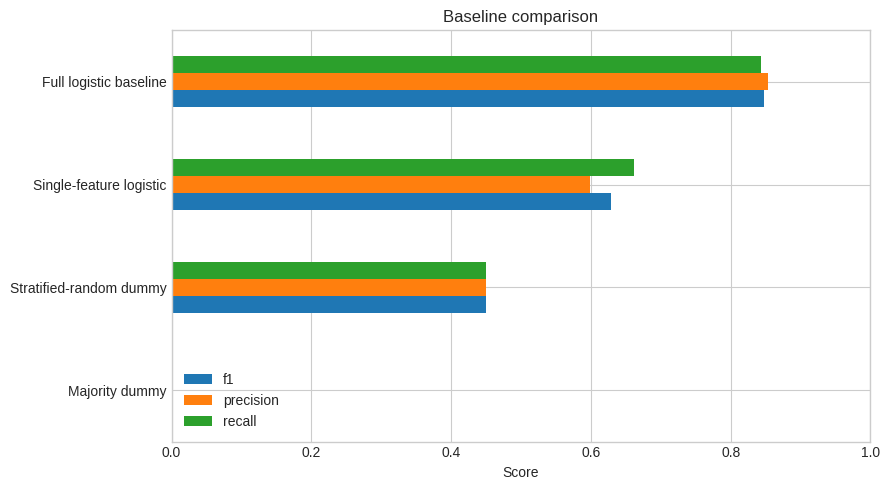

A majority prediction can have acceptable accuracy but F1 = 0 when it never predicts a scored penalty.


In [8]:
plot_data = baseline_results.set_index("method")[["f1", "precision", "recall"]].sort_values("f1")
ax = plot_data.plot.barh(figsize=(9, 5), title="Baseline comparison")
ax.set(xlabel="Score", ylabel="", xlim=(0, 1))
plt.tight_layout()
plt.show()
print("A majority prediction can have acceptable accuracy but F1 = 0 when it never predicts a scored penalty.")

## 4. Validation alternatives

- **Stratified holdout:** one train/validation split with similar class ratios. Fast, but sensitive to which rows were selected.
- **Stratified K-fold:** rotates through five validation folds. Every row is tested once; this is our main method.
- **Repeated stratified K-fold:** repeats K-fold with new shuffles. More stable, but slower.

We choose the validation protocol now and reuse its splits later. Preprocessing is not skipped: it is relearned inside each fold so the validation rows remain unseen.

`GroupKFold` requires meaningful repeated groups, but the supplied IDs are unique. Temporal validation requires event order, but no event date is supplied. `std_f1` shows how much fold scores vary.


In [9]:
full_pipeline = build_pipeline(
    FEATURES, LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
)

X_train, X_valid, y_train, y_valid = train_test_split(
    train[FEATURES], y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
holdout_model = clone(full_pipeline).fit(X_train, y_train)
holdout_probabilities = holdout_model.predict_proba(X_valid)[:, 1]
holdout_f1 = f1_score(y_valid, holdout_probabilities >= 0.50)

five_fold_scores = cross_val_score(full_pipeline, train[FEATURES], y, cv=cv, scoring="f1", n_jobs=-1)
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
repeated_scores = cross_val_score(full_pipeline, train[FEATURES], y, cv=repeated_cv, scoring="f1", n_jobs=-1)

validation_results = pd.DataFrame([
    ["Stratified holdout", 1, holdout_f1, np.nan],
    ["Stratified 5-fold", len(five_fold_scores), five_fold_scores.mean(), five_fold_scores.std()],
    ["Repeated stratified 5-fold", len(repeated_scores), repeated_scores.mean(), repeated_scores.std()],
], columns=["method", "validation_scores", "mean_f1", "std_f1"])
display(validation_results)

,method,validation_scores,mean_f1,std_f1
0,Stratified holdout,1,0.8483,NaN
1,Stratified 5-fold,5,0.8482,0.0049
2,Repeated stratified 5-fold,15,0.8485,0.0053


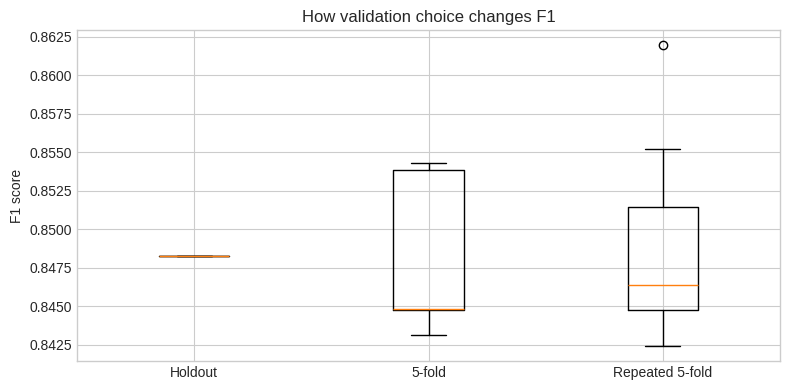

Five-fold range: 0.8432 to 0.8543
Repeated five-fold range: 0.8424 to 0.8620


In [10]:
score_groups = [[holdout_f1], five_fold_scores, repeated_scores]
labels = ["Holdout", "5-fold", "Repeated 5-fold"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(score_groups)
ax.set_xticklabels(labels)
ax.set(title="How validation choice changes F1", ylabel="F1 score")
plt.tight_layout()
plt.show()
print(f"Five-fold range: {five_fold_scores.min():.4f} to {five_fold_scores.max():.4f}")
print(f"Repeated five-fold range: {repeated_scores.min():.4f} to {repeated_scores.max():.4f}")

## 5. Why keep out-of-fold predictions?

An **out-of-fold (OOF) prediction** is made for a row by a model that did not train on that row. OOF probabilities let later notebooks compare thresholds, calibration, ensembles, and errors without contaminating validation.

In [11]:
best = baseline_results.iloc[0]
majority = baseline_results.loc[baseline_results["method"].eq("Majority dummy")].iloc[0]
print(f"Best baseline: {best['method']} | OOF F1: {best['f1']:.4f}")
print(f"Improvement over majority F1: {best['f1'] - majority['f1']:.4f}")
print("Decision: use stratified 5-fold OOF predictions for the phase comparisons.")
print("Repeated K-fold is a robustness check when the final choice is close.")

Best baseline: Full logistic baseline | OOF F1: 0.8482
Improvement over majority F1: 0.8482
Decision: use stratified 5-fold OOF predictions for the phase comparisons.
Repeated K-fold is a robustness check when the final choice is close.


## Other useful alternatives

- **Multiple-seed holdout:** repeat holdout with different random seeds; simpler than repeated K-fold.
- **Nested cross-validation:** adds an outer loop around tuning; reliable but expensive.
- **Bootstrap validation:** repeatedly sample rows with replacement; useful for uncertainty estimates.
- **Leave-one-group-out:** validate on one full group at a time when real groups exist.

They are not run here because stratified K-fold matches this dataset and keeps the beginner workflow manageable.

In [12]:
results_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)
baseline_path = results_dir / "02_baselines.csv"
validation_path = results_dir / "02_validation_methods.csv"
baseline_results.to_csv(baseline_path, index=False)
validation_results.to_csv(validation_path, index=False)
print(f"Saved: {baseline_path}")
print(f"Saved: {validation_path}")

Saved: /kaggle/working/02_baselines.csv
Saved: /kaggle/working/02_validation_methods.csv


## Why this validation decision is justified

**Technical evidence:** the full logistic baseline reaches about `0.848` OOF F1, five-fold validation tests every row once, and its variability is visible rather than hidden by one lucky holdout.

**Theoretical reason:** all later choices need an unchanged, leakage-safe measuring system. We therefore keep stratified five-fold OOF validation and fit every preprocessing operation inside its training folds.
